# Nhóm 21 - Apriori bằng Julia

In [3]:
import os, sys, subprocess
REPO_URL = "https://github.com/anhJ04/Frequent-Itemset.git"
PROJECT_SUBDIR = "21"

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    if not os.path.exists("/content/repo"):
        !git clone -q {REPO_URL} /content/repo
    %cd /content/repo/{PROJECT_SUBDIR}
    if subprocess.run("which julia", shell=True, capture_output=True).returncode != 0:
        !curl -fsSL https://julialang-s3.julialang.org/bin/linux/x64/1.11/julia-1.11.4-linux-x86_64.tar.gz -o /tmp/julia.tar.gz
        !tar -xzf /tmp/julia.tar.gz -C /usr --strip-components 1
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")
print("Thư mục làm việc:", os.getcwd())
!julia --version
!julia --project=. -e 'using Pkg; Pkg.instantiate()'

/content/repo/21
Thư mục làm việc: /content/repo/21
julia version 1.12.6
┌ Warning: The active manifest file has dependencies that were resolved with a different julia version (1.13.4). Unexpected behavior may occur.
└ @ /content/repo/21/Manifest.toml:0
   Installed DataStructures ─ v0.19.7
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2
  ◐ OrderedCollections
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2
  ◓ OrderedCollections
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2
  ◑ OrderedCollections
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2
  ◒ OrderedCollections
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2
  ◐ OrderedCollections
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2
  ◓ OrderedCollections
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2
  ◑ OrderedCollections
Precompiling packages  ╺━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 0/2
  ◒

## 1. Unit test

So sánh 4 biến thể với kết quả của SPMF trên 5 CSDL và với brute force trên dữ liệu ngẫu nhiên.

In [4]:
!julia --project=. tests/runtests.jl

Test Summary: | Pass  Total   Time
Apriori       |  349    349  24.1s

Tỉ lệ khớp so với SPMF
CSDL       minsup  thuật toán       SPMF     nhóm     khớp    tỉ lệ
toy        2       basic               9        9        9  100.00%
toy        2       optimized           9        9        9  100.00%
toy        2       tid                 9        9        9  100.00%
toy        2       hybrid              9        9        9  100.00%
chess      0.8     basic            8227     8227     8227  100.00%
chess      0.8     optimized        8227     8227     8227  100.00%
chess      0.8     tid              8227     8227     8227  100.00%
chess      0.8     hybrid           8227     8227     8227  100.00%
mushrooms  0.5     basic             163      163      163  100.00%
mushrooms  0.5     optimized         163      163      163  100.00%
mushrooms  0.5     tid               163      163      163  100.00%
mushrooms  0.5     hybrid            163      163      163  100.00%
retail     0.02    bas

## 2. Chạy CLI và so sánh với SPMF

In [5]:
!julia --project=. run_cli.jl --input data/benchmark/chess.txt --minsup 0.8 --algo hybrid -o results/demo/chess_0.8
!python compare_outputs.py tests/ref/chess_0.8.txt results/demo/chess_0.8_list.txt
!head -5 results/demo/chess_0.8_list.txt

  Activating project at `/content/repo/21`
[1/3] Đang đọc CSDL từ: data/benchmark/chess.txt
[2/3] Đang chạy thuật toán Apriori (hybrid) | Minsup tương đối: 0.8 (Tối thiểu 2557 giao dịch)
[3/3] Hoàn thành trong: 3.7034s | Bộ nhớ cấp phát: 547.09 MB. Tìm thấy 8227 frequent itemsets.
Đang ghi danh sách tập phổ biến ra: results/demo/chess_0.8_list.txt
Đang ghi thống kê ra: results/demo/chess_0.8_stat.txt
SPMF: 8227 tập | Tự cài đặt: 8227 tập
Thiếu: 0 | Thừa: 0 | Sai support: 0
KẾT QUẢ: KHỚP HOÀN TOÀN
3 #SUP: 2839
5 #SUP: 2971
7 #SUP: 3076
9 #SUP: 2874
25 #SUP: 2860


## 3. Thực nghiệm

Ô dưới chạy bản rút gọn (Chess, Mushroom) để kiểm tra trên Colab. Kết quả đầy đủ chạy trên máy nhóm, lưu trong `results/exp/`.

In [6]:
!rm -rf results/exp_colab
!python bench/run_experiments.py --datasets chess mushrooms --exps runtime --algos optimized hybrid --no-spmf --cap 30 --out results/exp_colab
!python bench/plot_results.py --dir results/exp_colab
import pandas as pd
pd.read_csv("results/exp_colab/runtime.csv")[["dataset", "algo", "minsup", "count", "max_k", "time", "status"]]

[16:07:25] == runtime: chess
[16:07:30]   runtime chess       x=0.9     optimized -> 622 itemsets, 0.00407 s
[16:07:36]   runtime chess       x=0.9     hybrid    -> 622 itemsets, 0.11123 s
[16:07:42]   runtime chess       x=0.85    optimized -> 2669 itemsets, 0.01026 s
[16:07:47]   runtime chess       x=0.85    hybrid    -> 2669 itemsets, 0.68919 s
[16:07:53]   runtime chess       x=0.8     optimized -> 8227 itemsets, 0.03502 s
[16:08:01]   runtime chess       x=0.8     hybrid    -> 8227 itemsets, 2.11133 s
[16:08:07]   runtime chess       x=0.75    optimized -> 20993 itemsets, 0.13084 s
[16:08:18]   runtime chess       x=0.75    hybrid    -> 20993 itemsets, 6.38432 s
[16:08:24]   runtime chess       x=0.7     optimized -> 48731 itemsets, 0.64584 s
[16:08:47]   runtime chess       x=0.7     hybrid    -> 48731 itemsets, 17.82498 s
[16:08:53]   runtime chess       x=0.65    optimized -> 111239 itemsets, 1.47515 s
[16:09:23]   runtime chess       x=0.65    hybrid    -> timeout
[16:09:34] 

,dataset,algo,minsup,count,max_k,time,status
0,chess,optimized,0.90,622.0,7.0,0.00407,ok
1,chess,hybrid,0.90,622.0,7.0,0.11123,ok
2,chess,optimized,0.85,2669.0,8.0,0.01026,ok
3,chess,hybrid,0.85,2669.0,8.0,0.68919,ok
4,chess,optimized,0.80,8227.0,10.0,0.03502,ok
5,chess,hybrid,0.80,8227.0,10.0,2.11133,ok
6,chess,optimized,0.75,20993.0,11.0,0.13084,ok
7,chess,hybrid,0.75,20993.0,11.0,6.38432,ok
8,chess,optimized,0.70,48731.0,13.0,0.64584,ok
9,chess,hybrid,0.70,48731.0,13.0,17.82498,ok


results/exp_colab/fig/runtime_vs_minsup.png


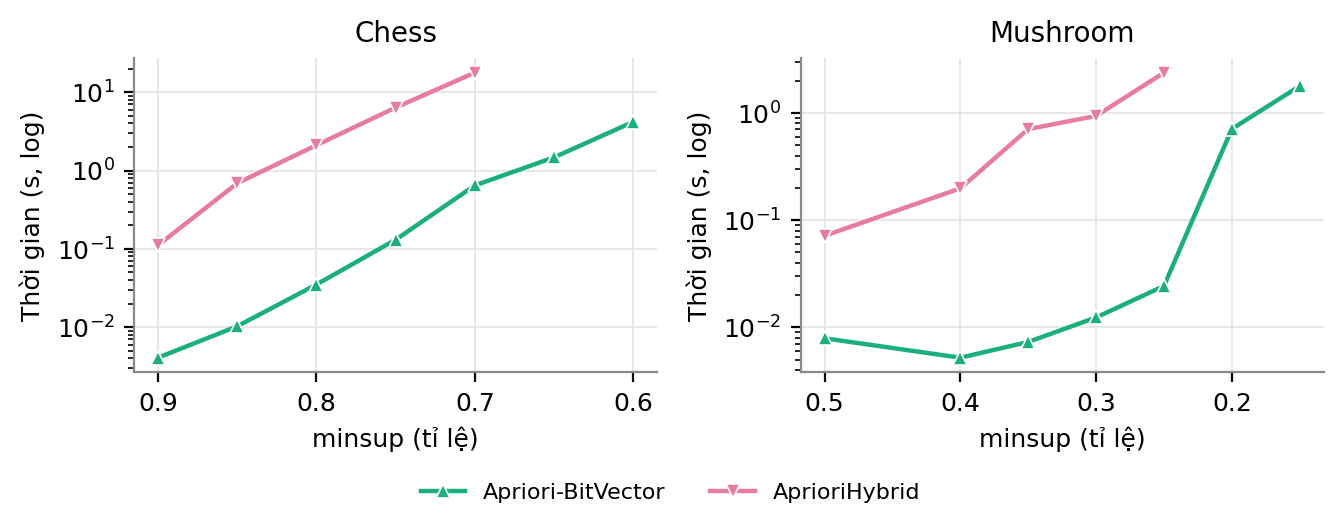

results/exp_colab/fig/count_vs_minsup.png


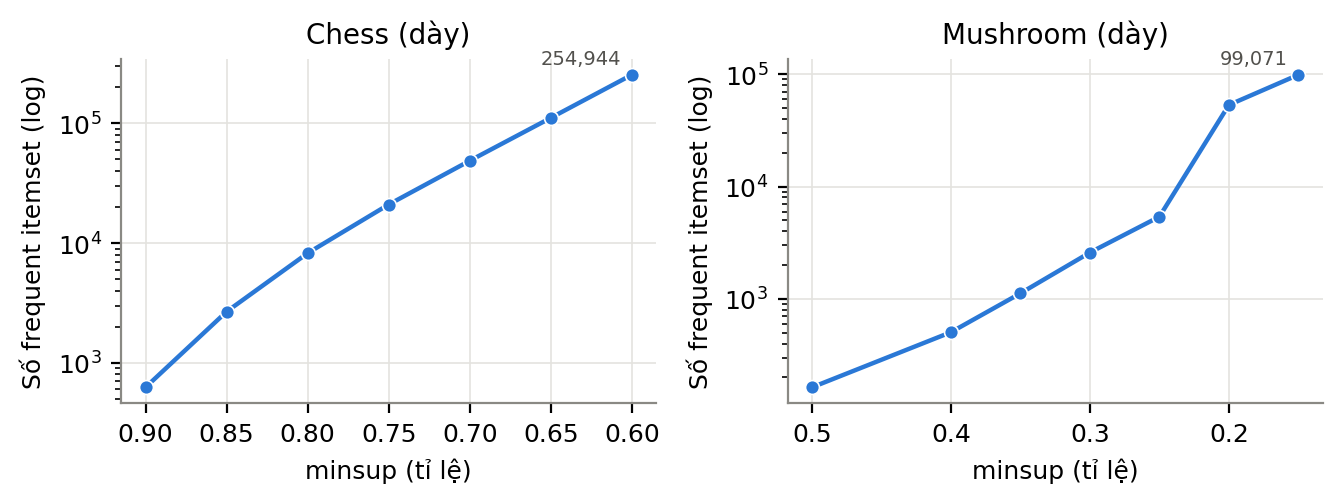

results/exp_colab/fig/memory_peak.png


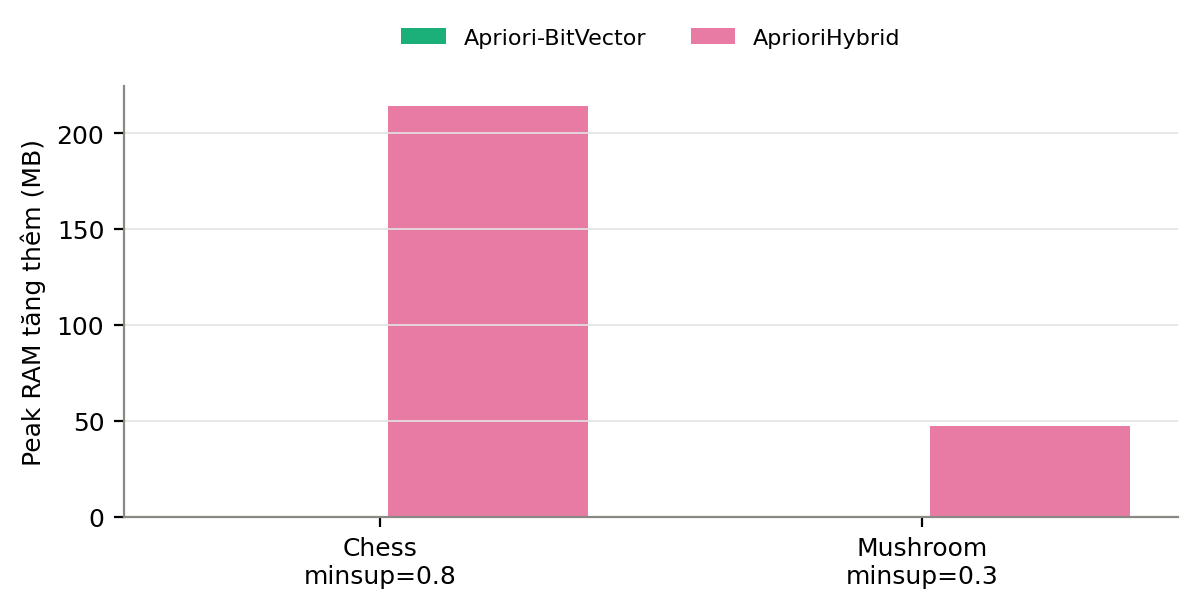

results/exp/fig/runtime_vs_minsup.png


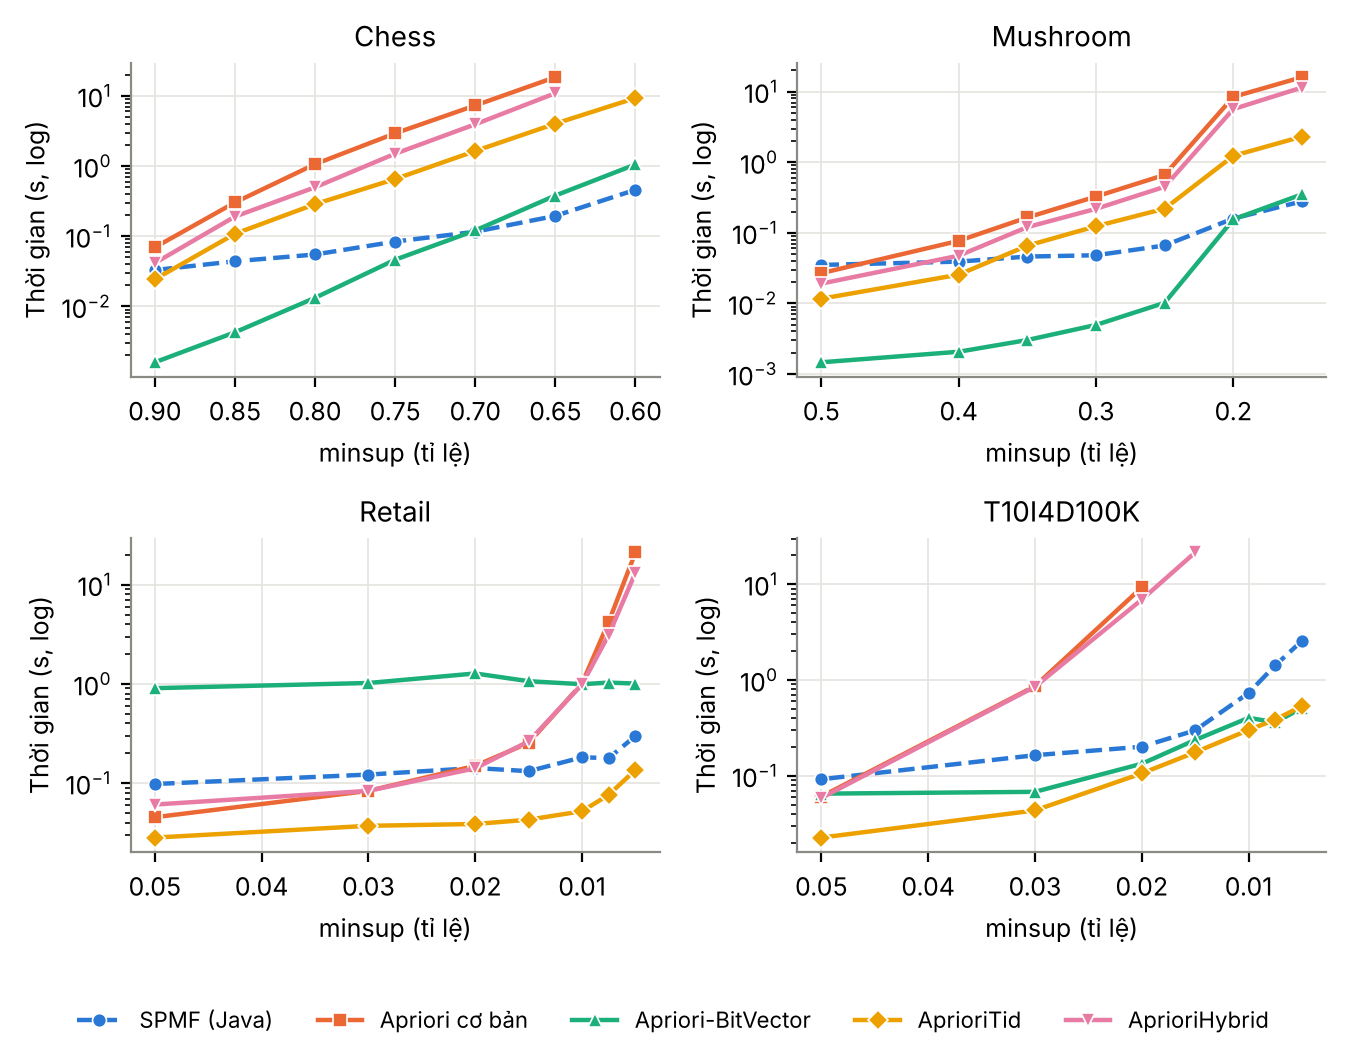

results/exp/fig/count_vs_minsup.png


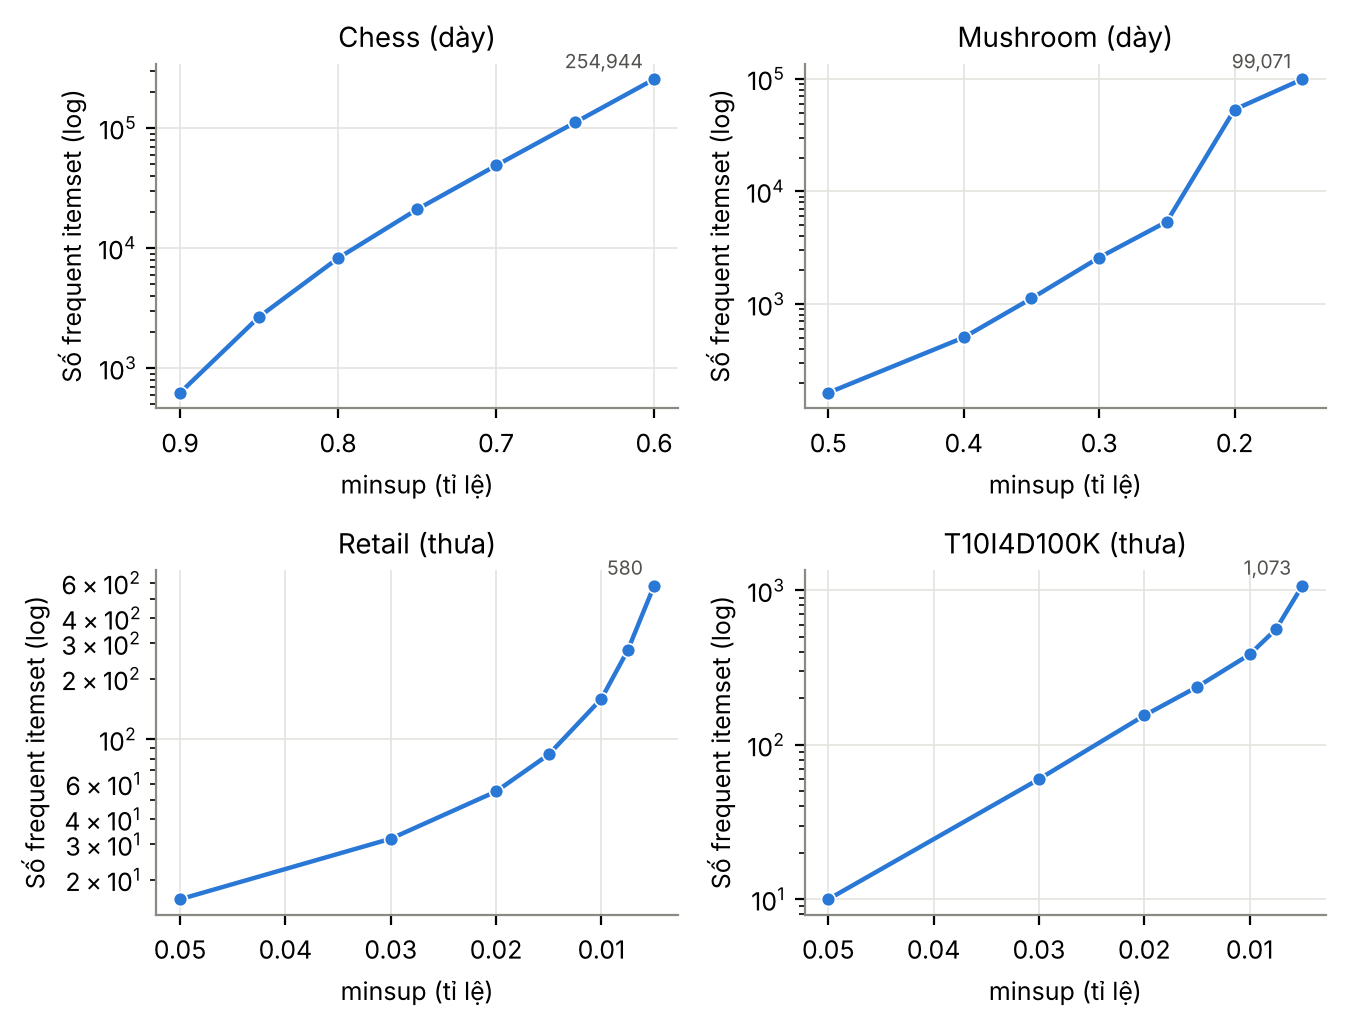

results/exp/fig/memory_peak.png


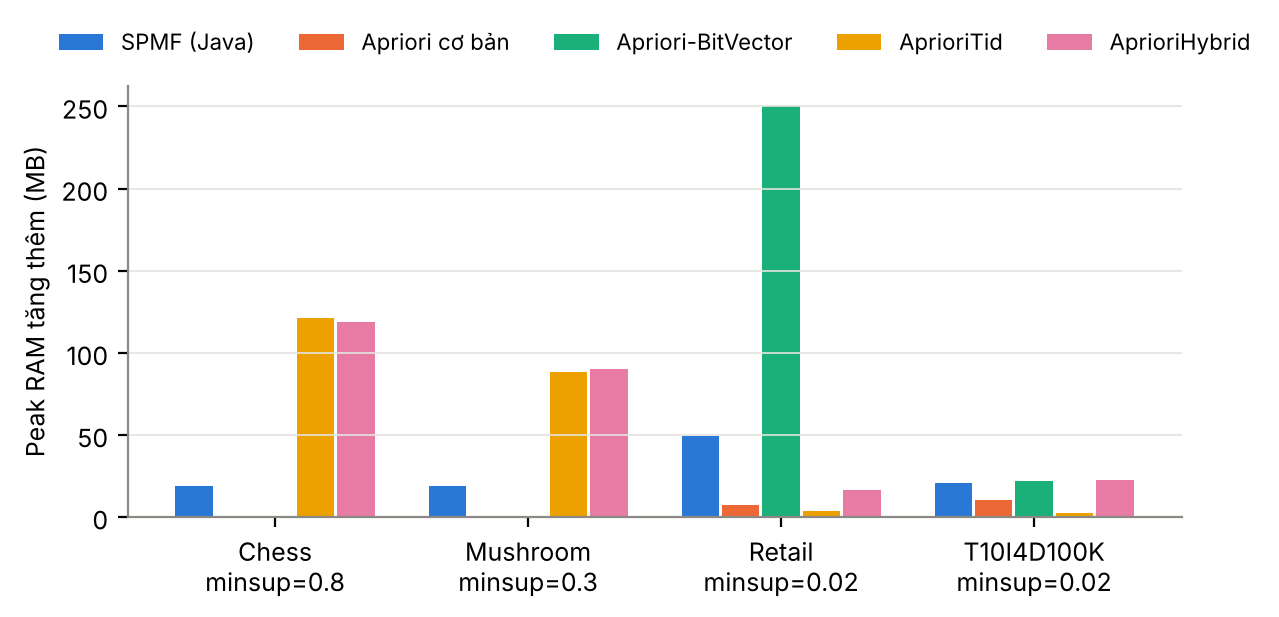

results/exp/fig/scalability.png


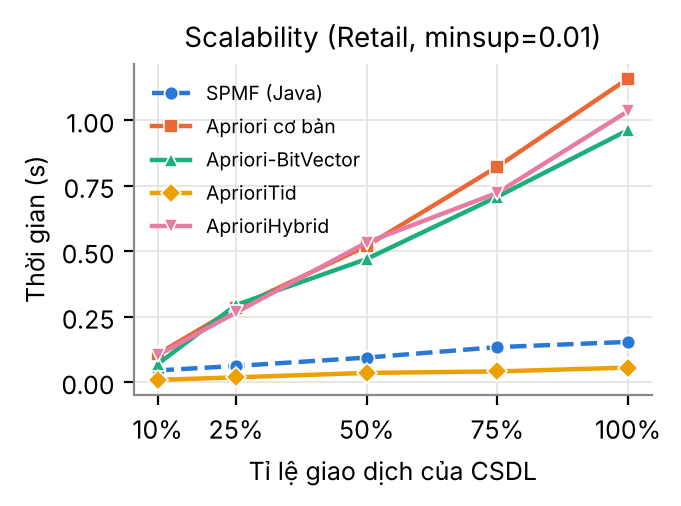

results/exp/fig/length_effect.png


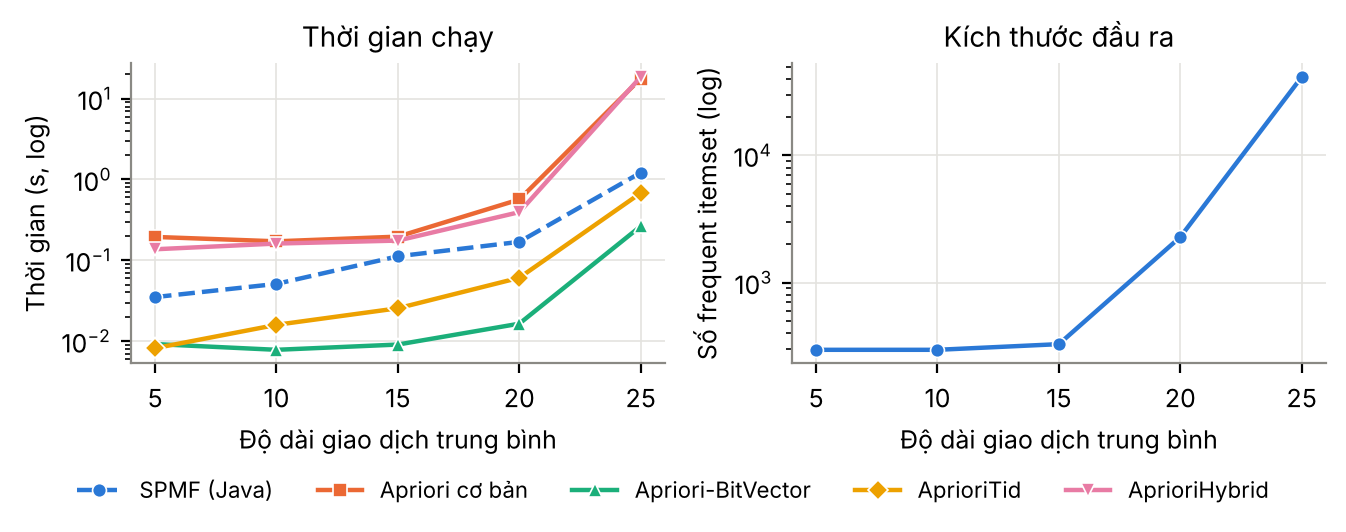

In [7]:
from IPython.display import Image, display
for d in ["results/exp_colab/fig", "results/exp/fig"]:
    for name in ["runtime_vs_minsup", "count_vs_minsup", "memory_peak", "scalability", "length_effect"]:
        p = f"{d}/{name}.png"
        if os.path.exists(p):
            print(p); display(Image(p, width=650))

## 4. Ứng dụng 1: Phân tích giỏ hàng (Groceries)

Dữ liệu: 9.835 hoá đơn, 169 nhóm hàng.

Cách biến đổi: mỗi hoá đơn là một giao dịch, mỗi nhóm hàng được đánh số thành một item. Dữ liệu thưa (khoảng 4,4 món mỗi hoá đơn) nên hợp với Apriori.

Ngưỡng: minsup = 1%, minconf = 30%.

In [8]:
import csv, json
from collections import Counter
rows = []
with open("data/raw/groceries.csv", encoding="utf-8") as f:
    for r in csv.reader(f):
        items = sorted({x.strip() for x in r if x.strip()})
        if items:
            rows.append(items)
names = sorted({x for r in rows for x in r})
name2id = {n: i for i, n in enumerate(names, 1)}
os.makedirs("data/processed", exist_ok=True)
with open("data/processed/groceries.txt", "w") as f:
    for r in rows:
        f.write(" ".join(str(name2id[x]) for x in sorted(r, key=name2id.get)) + "\n")
json.dump({str(i): n for n, i in name2id.items()}, open("data/processed/groceries_items.json", "w"),
          ensure_ascii=False, indent=0)
N = len(rows)
print(f"{N} giao dịch | {len(names)} item | độ dài TB {sum(map(len, rows)) / N:.2f}")
print("Mặt hàng phổ biến nhất:", Counter(x for r in rows for x in r).most_common(8))

9835 giao dịch | 169 item | độ dài TB 4.41
Mặt hàng phổ biến nhất: [('whole milk', 2513), ('other vegetables', 1903), ('rolls/buns', 1809), ('soda', 1715), ('yogurt', 1372), ('bottled water', 1087), ('root vegetables', 1072), ('tropical fruit', 1032)]


In [9]:
!julia --project=. apps/app_rules.jl data/processed/groceries.txt 0.01 0.3 results/app1/groceries_rules.csv hybrid

9835 giao dịch | minsup=0.01 (99) | hybrid: 333 tập phổ biến trong 2.983 s | 125 luật (minconf=0.3) -> results/app1/groceries_rules.csv


In [10]:
id2name = json.load(open("data/processed/groceries_items.json"))
dec = lambda s: ", ".join(id2name[i] for i in str(s).split())
rules = pd.read_csv("results/app1/groceries_rules.csv")
rules["Nếu mua (X)"] = rules["antecedent"].map(dec)
rules["thì mua (Y)"] = rules["consequent"].map(dec)
print(f"Tổng số luật (support ≥ 1%, confidence ≥ 30%): {len(rules)}")
top10 = rules.head(10)[["Nếu mua (X)", "thì mua (Y)", "support", "confidence", "lift"]].round(3)
top10.index = range(1, 11)
top10

Tổng số luật (support ≥ 1%, confidence ≥ 30%): 125


,Nếu mua (X),thì mua (Y),support,confidence,lift
1,"citrus fruit, other vegetables",root vegetables,0.010,0.359,3.295
2,"other vegetables, tropical fruit",root vegetables,0.012,0.343,3.145
3,beef,root vegetables,0.017,0.331,3.040
4,"citrus fruit, root vegetables",other vegetables,0.010,0.586,3.030
5,"root vegetables, tropical fruit",other vegetables,0.012,0.585,3.021
6,"other vegetables, whole milk",root vegetables,0.023,0.310,2.842
7,"curd, whole milk",yogurt,0.010,0.385,2.761
8,"rolls/buns, root vegetables",other vegetables,0.012,0.502,2.595
9,"root vegetables, yogurt",other vegetables,0.013,0.500,2.584
10,"tropical fruit, whole milk",yogurt,0.015,0.358,2.568


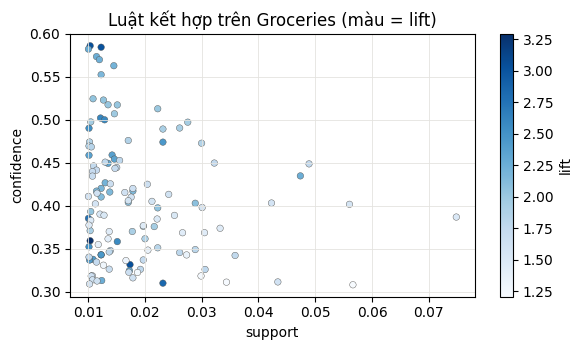

In [11]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(6, 3.6))
sc = ax.scatter(rules["support"], rules["confidence"], c=rules["lift"], cmap="Blues", s=22,
                edgecolors="#52514d", linewidths=0.3)
ax.set_xlabel("support"); ax.set_ylabel("confidence")
ax.set_title("Luật kết hợp trên Groceries (màu = lift)")
fig.colorbar(sc, label="lift"); ax.grid(color="#e4e3df", linewidth=0.6)
plt.tight_layout(); plt.savefig("results/app1/rules_scatter.png", dpi=200); plt.show()

In [12]:
# Độ nhạy theo ngưỡng: chạy lại cài đặt Julia của nhóm với nhiều cặp (minsup, minconf)
rows_s = []
for ms in (0.02, 0.01, 0.005):
    for mc in (0.3, 0.5):
        out = f"results/app1/sens_{ms}_{mc}.csv"
        subprocess.run(["julia", "--project=.", "apps/app_rules.jl", "data/processed/groceries.txt",
                        str(ms), str(mc), out, "hybrid"], check=True, capture_output=True)
        r = pd.read_csv(out)
        n_fi = sum(1 for l in open(out.replace(".csv", "_itemsets.txt")) if "#SUP" in l)
        rows_s.append({"minsup": ms, "minconf": mc, "#tập phổ biến": n_fi, "#luật": len(r),
                       "lift lớn nhất": round(r["lift"].max(), 2) if len(r) else None})
print("Vế phải phổ biến nhất của các luật (minsup 1%, minconf 30%):",
      rules["thì mua (Y)"].value_counts().head(5).to_dict())
print("Số luật theo |X|:", rules["antecedent"].astype(str).str.split().str.len().value_counts().sort_index().to_dict())
pd.DataFrame(rows_s)

Vế phải phổ biến nhất của các luật (minsup 1%, minconf 30%): {'whole milk': 66, 'other vegetables': 44, 'yogurt': 9, 'root vegetables': 4, 'rolls/buns': 2}
Số luật theo |X|: {1: 69, 2: 56}


,minsup,minconf,#tập phổ biến,#luật,lift lớn nhất
0,0.020,0.3,122,37,2.84
1,0.020,0.5,122,1,2.01
2,0.010,0.3,333,125,3.30
3,0.010,0.5,333,15,3.03
4,0.005,0.3,1001,487,4.72
5,0.005,0.5,1001,120,3.69


### Nhận xét

- Phần lớn luật top đầu là rau củ và trái cây đi cùng nhau, lift khoảng 3. Khách mua hai loại đồ tươi thì hay mua thêm loại thứ ba. Nên xếp các quầy này gần nhau hoặc làm combo.
- beef ⇒ root vegetables (lift 3,04): thịt bò thường mua kèm rau củ để nấu. Có thể bày rau củ gần quầy thịt.
- Nhóm sữa: curd, whole milk ⇒ yogurt. Có thể làm gói bữa sáng sữa chua và trái cây.
- whole milk và other vegetables xuất hiện trong rất nhiều luật vì bản thân chúng được mua nhiều. Vì vậy nhóm xếp theo lift thay vì confidence.
- Hạn chế: lift chỉ cho biết hai món hay đi cùng nhau, không phải nguyên nhân. Dữ liệu chỉ có 30 ngày của một cửa hàng.

## 5. Ứng dụng 2: Genome SARS-CoV-2

Dữ liệu: genome MT745584, dài 29.860 nucleotide.

Cách biến đổi: cắt genome thành các đoạn 100 nucleotide, bước 50. Mỗi đoạn là một giao dịch, item là các 3-mer (chuỗi 3 nucleotide) có trong đoạn.

Nhóm có thử k = 6 nhưng dữ liệu quá thưa, chỉ ra itemset 1 phần tử. Với k = 3 mới có các tổ hợp để phân tích (bảng ở ô dưới).

In [13]:
# Chọn tham số biến đổi: thử nhiều cấu hình (k, W, S, minsup) bằng cài đặt Julia của nhóm
from itertools import product
genome = "".join(l.strip().upper() for l in open("data/benchmark/MT745584.txt")
                 if l.strip() and not l.startswith(">"))
def make_tx(K, W, S, path):
    km = {"".join(p): i for i, p in enumerate(product("ACGT", repeat=K), 1)}
    with open(path, "w") as f:
        n = 0
        for s in range(0, len(genome) - W + 1, S):
            w = genome[s:s + W]
            ids = sorted({km[w[j:j + K]] for j in range(W - K + 1) if w[j:j + K] in km})
            f.write(" ".join(map(str, ids)) + "\n"); n += 1
    return n
os.makedirs("results/app2", exist_ok=True)
grid_rows = []
for K, W, S, ms in [(6, 100, 95, 0.1), (4, 100, 50, 0.5), (4, 150, 75, 0.6), (3, 100, 50, 0.8)]:
    path = f"data/processed/covid_k{K}_w{W}_s{S}.txt"
    n = make_tx(K, W, S, path)
    out = f"results/app2/grid_k{K}_w{W}_s{S}_{ms}"
    subprocess.run(["julia", "--project=.", "run_cli.jl", "--input", path, "--minsup", str(ms),
                    "--algo", "hybrid", "-o", out], check=True, capture_output=True)
    sizes = Counter(len(l.split("#SUP:")[0].split()) for l in open(out + "_list.txt") if "#SUP" in l)
    grid_rows.append({"k": K, "W": W, "S": S, "minsup": ms, "#giao dịch": n, "#itemset": sum(sizes.values()),
                      "theo kích thước": dict(sorted(sizes.items()))})
pd.DataFrame(grid_rows)

,k,W,S,minsup,#giao dịch,#itemset,theo kích thước
0,6,100,95,0.1,314,12,{1: 12}
1,4,100,50,0.5,596,23,{1: 23}
2,4,150,75,0.6,397,50,"{1: 47, 2: 3}"
3,3,100,50,0.8,596,186,"{1: 29, 2: 106, 3: 51}"


In [14]:
from itertools import product
K, W, S = 3, 100, 50
genome = "".join(l.strip().upper() for l in open("data/benchmark/MT745584.txt")
                 if l.strip() and not l.startswith(">"))
kmer2id = {"".join(p): i for i, p in enumerate(product("ACGT", repeat=K), 1)}
id2kmer = {str(i): k for k, i in kmer2id.items()}
starts = list(range(0, len(genome) - W + 1, S))
with open("data/processed/covid_k3.txt", "w") as f:
    for s in starts:
        w = genome[s:s + W]
        ids = sorted({kmer2id[w[j:j + K]] for j in range(W - K + 1) if w[j:j + K] in kmer2id})
        f.write(" ".join(map(str, ids)) + "\n")
gc = (genome.count("G") + genome.count("C")) / len(genome)
print(f"Genome: {len(genome):,} nt | GC = {gc:.1%} | {len(starts)} giao dịch | {len(kmer2id)} item (3-mer)")

Genome: 29,860 nt | GC = 38.0% | 596 giao dịch | 64 item (3-mer)


In [15]:
# (a) tổ hợp 3-mer phổ biến: minsup 80% và 70% — chạy bằng cài đặt Julia của nhóm
!julia --project=. run_cli.jl --input data/processed/covid_k3.txt --minsup 0.8 --algo hybrid -o results/app2/covid_k3_0.8
!julia --project=. run_cli.jl --input data/processed/covid_k3.txt --minsup 0.7 --algo hybrid -o results/app2/covid_k3_0.7
# (b) support của cả 64 3-mer (chỉ mức 1: --maxlen 1, minsup rất thấp)
!julia --project=. run_cli.jl --input data/processed/covid_k3.txt --minsup 0.001 --maxlen 1 --algo hybrid -o results/app2/covid_k3_single

  Activating project at `/content/repo/21`
[1/3] Đang đọc CSDL từ: data/processed/covid_k3.txt
[2/3] Đang chạy thuật toán Apriori (hybrid) | Minsup tương đối: 0.8 (Tối thiểu 477 giao dịch)
[3/3] Hoàn thành trong: 2.1138s | Bộ nhớ cấp phát: 98.75 MB. Tìm thấy 186 frequent itemsets.
Đang ghi danh sách tập phổ biến ra: results/app2/covid_k3_0.8_list.txt
Đang ghi thống kê ra: results/app2/covid_k3_0.8_stat.txt
  Activating project at `/content/repo/21`
[1/3] Đang đọc CSDL từ: data/processed/covid_k3.txt
[2/3] Đang chạy thuật toán Apriori (hybrid) | Minsup tương đối: 0.7 (Tối thiểu 418 giao dịch)
[3/3] Hoàn thành trong: 3.099s | Bộ nhớ cấp phát: 142.77 MB. Tìm thấy 2527 frequent itemsets.
Đang ghi danh sách tập phổ biến ra: results/app2/covid_k3_0.7_list.txt
Đang ghi thống kê ra: results/app2/covid_k3_0.7_stat.txt
  Activating project at `/content/repo/21`
[1/3] Đang đọc CSDL từ: data/processed/covid_k3.txt
[2/3] Đang chạy thuật toán Apriori (hybrid) | Minsup tương đối: 0.001 (Tối thiểu 1 g

In [16]:
def load_fi(path):
    out = []
    for line in open(path):
        if "#SUP:" in line:
            left, sup = line.split("#SUP:")
            out.append(([id2kmer[i] for i in left.split()], int(sup)))
    return out

Nt = len(starts)
for ms in ("0.8", "0.7"):
    fi = load_fi(f"results/app2/covid_k3_{ms}_list.txt")
    by = Counter(len(k) for k, _ in fi)
    n_cg = sum(any("CG" in x for x in k) for k, _ in fi)
    print(f"minsup={ms}: {len(fi)} itemset, theo kích thước {dict(sorted(by.items()))}, "
          f"số itemset chứa 3-mer có 'CG': {n_cg}")

fi = load_fi("results/app2/covid_k3_0.8_list.txt")
top3 = sorted((x for x in fi if len(x[0]) == 3), key=lambda x: -x[1])[:10]
pd.DataFrame([{"tổ hợp 3-mer": " + ".join(k), "support": s, "% đoạn genome": round(100 * s / Nt, 1)}
              for k, s in top3], index=range(1, len(top3) + 1))

minsup=0.8: 186 itemset, theo kích thước {1: 29, 2: 106, 3: 51}, số itemset chứa 3-mer có 'CG': 0
minsup=0.7: 2527 itemset, theo kích thước {1: 41, 2: 458, 3: 1149, 4: 769, 5: 110}, số itemset chứa 3-mer có 'CG': 0


,tổ hợp 3-mer,support,% đoạn genome
1,GTT + TTA + TTG,495,83.1
2,ACA + TTA + TTG,492,82.6
3,CTT + TTA + TTG,492,82.6
4,TGT + TTA + TTG,489,82.0
5,TTA + TTG + TTT,489,82.0
6,AAT + TTA + TTG,488,81.9
7,AAT + ATT + TTG,487,81.7
8,ATT + TTA + TTG,487,81.7
9,CTT + GTT + TTG,486,81.5
10,TAA + TTA + TTG,486,81.5


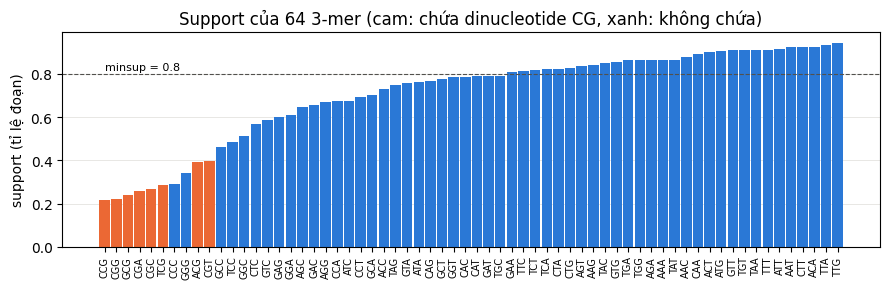

8 3-mer hiếm nhất: [('CCG', 0.215), ('CGG', 0.22), ('GCG', 0.238), ('CGA', 0.257), ('CGC', 0.267), ('TCG', 0.285), ('CCC', 0.292), ('GGG', 0.342)]
CpG quan sát/kỳ vọng = 0.41  (1.0 = không thiên lệch)


In [17]:
single = sorted(((k[0], s / Nt) for k, s in load_fi("results/app2/covid_k3_single_list.txt")),
                key=lambda x: x[1])
has_cg = [("CG" in k) for k, _ in single]
fig, ax = plt.subplots(figsize=(9, 3))
ax.bar(range(len(single)), [s for _, s in single], width=0.9,
       color=["#eb6834" if c else "#2a78d6" for c in has_cg])
ax.set_xticks(range(len(single))); ax.set_xticklabels([k for k, _ in single], rotation=90, fontsize=7)
ax.axhline(0.8, color="#52514d", lw=0.8, ls="--"); ax.text(0, 0.82, "minsup = 0.8", fontsize=8)
ax.set_ylabel("support (tỉ lệ đoạn)")
ax.set_title("Support của 64 3-mer (cam: chứa dinucleotide CG, xanh: không chứa)")
ax.grid(axis="y", color="#e4e3df", lw=0.6); ax.set_axisbelow(True)
plt.tight_layout(); plt.savefig("results/app2/kmer_support.png", dpi=200); plt.show()

print("8 3-mer hiếm nhất:", [(k, round(s, 3)) for k, s in single[:8]])
# tỉ lệ quan sát / kỳ vọng của dinucleotide CG (đo mức ức chế CpG)
L = len(genome)
obs = sum(genome[i:i + 2] == "CG" for i in range(L - 1)) / (L - 1)
exp = genome.count("C") / L * genome.count("G") / L
print(f"CpG quan sát/kỳ vọng = {obs / exp:.2f}  (1.0 = không thiên lệch)")

### Nhận xét

- Không có itemset phổ biến nào chứa 3-mer có "CG". Cả 8 3-mer chứa CG đều nằm trong nhóm hiếm nhất. Tỉ lệ CG quan sát/kỳ vọng khoảng 0,4. Đây là hiện tượng ức chế CpG đã được ghi nhận ở SARS-CoV-2, thường được giải thích là virus tránh bị protein ZAP của vật chủ nhận diện.
- Các tổ hợp phổ biến nhất giàu T (U trên RNA), đúng với việc genome này có GC thấp (38%).
- Có thể dùng các tập k-mer phổ biến làm đặc trưng để phân loại virus hoặc tìm đoạn genome bất thường.
- Hạn chế: chỉ dùng một genome, nên kết quả phản ánh thành phần nucleotide chứ chưa phải motif chức năng.